## 1. Importar las bibliotecas y localizar la carpeta del proyecto

El archivo `modeling.py` contiene funciones reutilizables por el cuaderno y por la página web. Así se evita que ambos lados apliquen reglas de limpieza diferentes.

In [15]:
from pathlib import Path
import hashlib
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import ConfusionMatrixDisplay

# Si se abre el cuaderno desde la carpeta notebooks, sube un nivel.
PROJECT_DIR = Path.cwd().resolve()
if not (PROJECT_DIR / "modeling.py").exists():
    PROJECT_DIR = PROJECT_DIR.parent
if not (PROJECT_DIR / "modeling.py").exists():
    raise FileNotFoundError("Abre en VS Code la carpeta raíz proyecto_analitica_web.")

import sys
sys.path.insert(0, str(PROJECT_DIR))
from modeling import clean_dataset, train_models

DATA_PATH = PROJECT_DIR / "data" / "MASTER_CHART_F1000Research.xlsx"
TARGET = "GROUPS"
RANDOM_STATE = 42
TEST_SIZE = 0.20

print("Carpeta del proyecto:", PROJECT_DIR)
print("Dataset encontrado:", DATA_PATH.exists())

Carpeta del proyecto: C:\Users\pc\Downloads\Proyecto_Final_Dengue_Completo_CORREGIDO\proyecto_analitica_web
Dataset encontrado: True


## 2. Cargar la base de datos original

Se utiliza el archivo Excel recibido. El encabezado de la primera columna contiene un texto largo; se normaliza a `GROUPS` para trabajar con un nombre corto y consistente.

In [16]:
df_original = pd.read_excel(DATA_PATH, sheet_name="Sheet1")
df_original.columns = [str(col).strip() for col in df_original.columns]

# Normalizar el nombre de la variable objetivo sin modificar sus valores.
renamed_columns = {}
for col in df_original.columns:
    upper = col.upper()
    if "GROUPS" in upper and "DENGUE" in upper:
        renamed_columns[col] = TARGET

df_original = df_original.rename(columns=renamed_columns)

print(f"Filas originales: {df_original.shape[0]}")
print(f"Columnas originales: {df_original.shape[1]}")
display(df_original.head())

Filas originales: 303
Columnas originales: 25


,GROUPS,AGE,GENDER,DURATION OF FEVER,HEADACHE,MYALGIA,ABDOMINAL PAIN,RASH,VOMITING,BREATHLESSNESS,...,LOWEST WBC,HIGHEST WBC,PLATELET COUNT,ALT,CREATININE,FERRITIN,IV FLUIDS,ANTIBIOTICS,ANTIPYRETICS,STEROIDS
0,2,2,1,3,2,1,2,2,1,2,...,3400,5100,30000,53.0,0.62,4167.0,1,1,2,1
1,2,2,1,4,2,1,2,2,2,2,...,3000,5300,43000,21.0,0.43,108.0,1,2,2,2
2,1,1,2,3,2,1,2,2,2,2,...,2300,2600,129000,12.0,0.34,212.0,1,1,1,2
3,1,2,2,5,2,1,2,2,2,2,...,1500,4800,70000,171.0,0.80,1429.0,1,1,1,1
4,1,2,2,3,2,1,2,2,2,2,...,8600,9100,184000,45.0,0.44,NaN,1,2,1,2


## 3. Exploración inicial

Se revisan los tipos de datos, valores faltantes, registros duplicados y distribución de la variable objetivo antes de limpiar.

,tipo,valores_nulos,valores_unicos
GROUPS,int64,0,2
AGE,int64,0,2
GENDER,int64,0,2
DURATION OF FEVER,int64,0,10
HEADACHE,int64,0,2
MYALGIA,int64,0,2
ABDOMINAL PAIN,int64,0,2
RASH,int64,0,2
VOMITING,int64,0,2
BREATHLESSNESS,int64,0,2


Registros duplicados: 1
Distribución original de GROUPS:


,Registros
GROUPS,
1,240
2,63


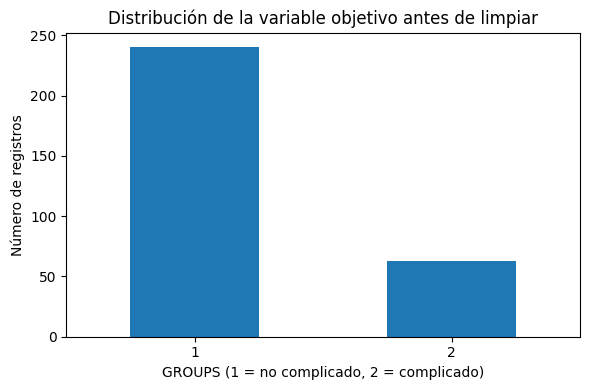

In [17]:
display(pd.DataFrame({
    "tipo": df_original.dtypes.astype(str),
    "valores_nulos": df_original.isna().sum(),
    "valores_unicos": df_original.nunique(dropna=True)
}))

print("Registros duplicados:", int(df_original.duplicated().sum()))
print("Distribución original de GROUPS:")
display(df_original[TARGET].value_counts(dropna=False).rename_axis("GROUPS").to_frame("Registros"))

ax = df_original[TARGET].value_counts().sort_index().plot(kind="bar", rot=0, figsize=(6, 4))
ax.set_title("Distribución de la variable objetivo antes de limpiar")
ax.set_xlabel("GROUPS (1 = no complicado, 2 = complicado)")
ax.set_ylabel("Número de registros")
plt.tight_layout()
plt.show()

## 4. Limpieza y transformación de datos

Se aplican las operaciones siguientes:

1. Normalizar encabezados y espacios.
2. Convertir cadenas numéricas a valores numéricos cuando corresponde.
3. Eliminar registros duplicados.
4. Eliminar registros sin etiqueta `GROUPS`.
5. Eliminar columnas vacías y predictoras constantes.
6. Convertir códigos categóricos documentados a etiquetas legibles (por ejemplo, género y respuestas Sí/No).
7. Crear dos variables derivadas: `WBC_RANGE` y `PLATELET_WBC_RATIO`.
8. Conservar valores faltantes en predictores; la imputación se ajusta dentro del pipeline utilizando solo los datos de entrenamiento.

Las reglas se comparten con `modeling.py`, el mismo módulo que emplea la aplicación web.

In [18]:
df_limpio, resumen_limpieza = clean_dataset(df_original, TARGET)

print("Resumen de limpieza:")
for clave, valor in resumen_limpieza.items():
    print(f"- {clave}: {valor}")

print("\nDimensiones después de limpiar:", df_limpio.shape)
display(df_limpio.head())

Resumen de limpieza:
- filas_iniciales: 303
- columnas_iniciales: 25
- filas_duplicadas_eliminadas: 1
- filas_sin_objetivo_eliminadas: 0
- columnas_vacias_eliminadas: []
- columnas_constantes_eliminadas: []
- columnas_convertidas_a_numerico: []
- variables_derivadas_creadas: ['WBC_RANGE', 'PLATELET_WBC_RATIO']
- categorias_decodificadas: ['AGE', 'GENDER', 'HEADACHE', 'MYALGIA', 'ABDOMINAL PAIN', 'RASH', 'VOMITING', 'BREATHLESSNESS', 'BLEEDING', 'BP AT ADMISSION', 'ORGANOMEGALY', 'IV FLUIDS', 'ANTIBIOTICS', 'ANTIPYRETICS', 'STEROIDS']
- filas_finales: 302
- columnas_finales: 27
- valores_faltantes_restantes: 114
- clases: {'1': 239, '2': 63}

Dimensiones después de limpiar: (302, 27)


,GROUPS,AGE,GENDER,DURATION OF FEVER,HEADACHE,MYALGIA,ABDOMINAL PAIN,RASH,VOMITING,BREATHLESSNESS,...,PLATELET COUNT,ALT,CREATININE,FERRITIN,IV FLUIDS,ANTIBIOTICS,ANTIPYRETICS,STEROIDS,WBC_RANGE,PLATELET_WBC_RATIO
0,2,Mayor de 6 años,Masculino,3,No,Sí,No,No,Sí,No,...,30000,53.0,0.62,4167.0,Sí,Sí,No,Sí,1700,5.882353
1,2,Mayor de 6 años,Masculino,4,No,Sí,No,No,No,No,...,43000,21.0,0.43,108.0,Sí,No,No,No,2300,8.113208
2,1,Menor de 6 años,Femenino,3,No,Sí,No,No,No,No,...,129000,12.0,0.34,212.0,Sí,Sí,Sí,No,300,49.615385
3,1,Mayor de 6 años,Femenino,5,No,Sí,No,No,No,No,...,70000,171.0,0.80,1429.0,Sí,Sí,Sí,Sí,3300,14.583333
4,1,Mayor de 6 años,Femenino,3,No,Sí,No,No,No,No,...,184000,45.0,0.44,NaN,Sí,No,Sí,No,500,20.219780


### 4.1 Revisar los valores faltantes después de limpiar

Los faltantes de ferritina, ALT y creatinina se conservan. Se imputarán dentro del preprocesamiento de cada modelo: mediana para variables numéricas y moda para variables categóricas.

In [19]:
faltantes = df_limpio.isna().sum().sort_values(ascending=False)
display(faltantes[faltantes > 0].rename("valores faltantes").to_frame())
print("Total de valores faltantes:", int(df_limpio.isna().sum().sum()))

,valores faltantes
FERRITIN,112
ALT,1
CREATININE,1


Total de valores faltantes: 114


### 4.2 Distribución de clases después de limpiar

La clase 1 es dengue no complicado y la clase 2 es dengue complicado. La base está desbalanceada, por eso además de exactitud se revisará la sensibilidad de la clase 2.

,Registros
GROUPS,
1 - No complicado,239
2 - Complicado,63


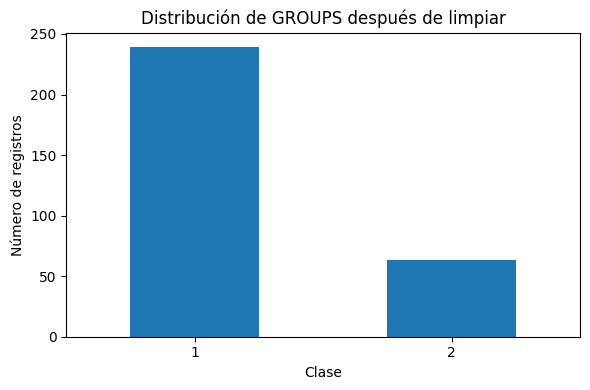

In [20]:
distribucion = df_limpio[TARGET].value_counts().sort_index()
display(distribucion.rename(index={"1": "1 - No complicado", "2": "2 - Complicado"}).to_frame("Registros"))

ax = distribucion.plot(kind="bar", rot=0, figsize=(6, 4))
ax.set_title("Distribución de GROUPS después de limpiar")
ax.set_xlabel("Clase")
ax.set_ylabel("Número de registros")
plt.tight_layout()
plt.show()

## 5. Crear la matriz de variables predictoras y definir la variable objetivo

Se excluyen del entrenamiento las variables de tratamiento `IV FLUIDS`, `ANTIBIOTICS`, `ANTIPYRETICS` y `STEROIDS`, porque podrían haberse registrado después de reconocer la gravedad o iniciar la atención. Si se usan predictores posteriores al evento que se desea anticipar, el modelo puede aprender información que no estaría disponible en el momento real de la predicción.

Las columnas `WBC_RANGE` y `PLATELET_WBC_RATIO` son variables derivadas exploratorias calculadas desde resultados de laboratorio ya presentes en el Excel; no representan umbrales ni reglas clínicas.

In [21]:
VARIABLES_DE_TRATAMIENTO = {"IV FLUIDS", "ANTIBIOTICS", "ANTIPYRETICS", "STEROIDS"}

features = [
    col for col in df_limpio.columns
    if col != TARGET and col not in VARIABLES_DE_TRATAMIENTO
]
X = df_limpio[features].copy()
y = df_limpio[TARGET].astype(str).copy()

print("Variable objetivo:", TARGET)
print("Número de variables predictoras:", len(features))
print("Variables excluidas por posible fuga de información:", sorted(VARIABLES_DE_TRATAMIENTO))
print("Variables utilizadas:")
for col in features:
    print("-", col)

print("\nDimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Variable objetivo: GROUPS
Número de variables predictoras: 22
Variables excluidas por posible fuga de información: ['ANTIBIOTICS', 'ANTIPYRETICS', 'IV FLUIDS', 'STEROIDS']
Variables utilizadas:
- AGE
- GENDER
- DURATION OF FEVER
- HEADACHE
- MYALGIA
- ABDOMINAL PAIN
- RASH
- VOMITING
- BREATHLESSNESS
- BLEEDING
- BP AT ADMISSION
- ORGANOMEGALY
- HB
- PCV
- LOWEST WBC
- HIGHEST WBC
- PLATELET COUNT
- ALT
- CREATININE
- FERRITIN
- WBC_RANGE
- PLATELET_WBC_RATIO

Dimensiones de X: (302, 22)
Dimensiones de y: (302,)


## 6. Dividir datos en entrenamiento y prueba

Se utiliza una división estratificada 80/20 para conservar aproximadamente la proporción de las dos clases en ambos conjuntos. La semilla 42 permite reproducir la partición. La imputación, estandarización y codificación se ajustan más adelante dentro de cada pipeline, sin aprender de los datos de prueba.

In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Registros para entrenamiento:", len(X_train))
print("Registros para prueba:", len(X_test))
print("Distribución en entrenamiento:")
display(y_train.value_counts().sort_index().rename("Registros").to_frame())
print("Distribución en prueba:")
display(y_test.value_counts().sort_index().rename("Registros").to_frame())

Registros para entrenamiento: 241
Registros para prueba: 61
Distribución en entrenamiento:


,Registros
GROUPS,
1,191
2,50


Distribución en prueba:


,Registros
GROUPS,
1,48
2,13


## 7. Definir los modelos y el preprocesamiento

Se comparan dos algoritmos de clasificación:

- **Regresión logística:** modelo estadístico de clasificación que estima la probabilidad de pertenecer a cada clase.
- **Red neuronal artificial (MLP):** red neuronal multicapa con dos capas ocultas de 64 y 32 neuronas, activación ReLU y optimizador Adam.

El preprocesamiento se aplica dentro de cada pipeline: mediana para faltantes numéricos, moda para faltantes categóricos, estandarización de variables numéricas y One-Hot Encoding para variables categóricas.

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

parametros_modelos = {
    "Regresión logística": {
        "clase": "LogisticRegression",
        "max_iter": 2000,
        "random_state": RANDOM_STATE
    },
    "Red neuronal artificial": {
        "clase": "MLPClassifier",
        "hidden_layer_sizes": (64, 32),
        "activation": "relu",
        "solver": "adam",
        "max_iter": 700,
        "random_state": RANDOM_STATE
    }
}
display(pd.DataFrame(parametros_modelos).T)

,clase,max_iter,random_state,hidden_layer_sizes,activation,solver
Regresión logística,LogisticRegression,2000,42,NaN,NaN,NaN
Red neuronal artificial,MLPClassifier,700,42,"(64, 32)",relu,adam


## 8. Entrenar los dos modelos

La función `train_models` del módulo compartido construye los pipelines, entrena los algoritmos sobre el mismo conjunto de entrenamiento y genera predicciones sobre el conjunto de prueba. La página web utiliza exactamente esta misma función cuando se solicita un nuevo entrenamiento.

In [24]:
resultado_entrenamiento = train_models(
    clean_df=df_limpio,
    target=TARGET,
    features=features,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

modelos_entrenados = resultado_entrenamiento["models"]
evaluaciones = resultado_entrenamiento["evaluation"]

print("Modelos entrenados:")
for nombre in modelos_entrenados:
    print("-", nombre)
print("Registros de entrenamiento:", resultado_entrenamiento["n_train"])
print("Registros de prueba:", resultado_entrenamiento["n_test"])

Modelos entrenados:
- Regresión logística
- Red neuronal artificial
Registros de entrenamiento: 241
Registros de prueba: 61


## 9. Evaluar y comparar los modelos

Se revisan accuracy, precisión ponderada, sensibilidad ponderada y F1 ponderado. Además se calcula la **sensibilidad de la clase 2**, que indica qué proporción de los registros complicados del conjunto de prueba fue detectada por el modelo.

In [25]:
filas_metricas = []
for nombre, metrica in evaluaciones.items():
    etiquetas = [str(x) for x in metrica["labels"]]
    matriz = np.asarray(metrica["confusion_matrix"])
    indice_clase_2 = etiquetas.index("2")
    total_clase_2 = matriz[indice_clase_2, :].sum()
    sensibilidad_clase_2 = (
        matriz[indice_clase_2, indice_clase_2] / total_clase_2
        if total_clase_2 else 0.0
    )
    filas_metricas.append({
        "Modelo": nombre,
        "Accuracy": metrica["accuracy"],
        "Precisión ponderada": metrica["precision"],
        "Sensibilidad ponderada": metrica["recall"],
        "F1 ponderado": metrica["f1"],
        "Sensibilidad clase 2": sensibilidad_clase_2
    })

comparacion = pd.DataFrame(filas_metricas).set_index("Modelo")
display(comparacion.style.format("{:.4f}"))

,Accuracy,Precisión ponderada,Sensibilidad ponderada,F1 ponderado,Sensibilidad clase 2
Modelo,,,,,
Regresión logística,0.9344,0.9334,0.9344,0.9324,0.7692
Red neuronal artificial,0.9016,0.9016,0.9016,0.9016,0.7692


## 10. Matrices de confusión y reportes de clasificación

Las filas de la matriz representan la clase real y las columnas la clase predicha. Los errores en la clase 2 son especialmente importantes para interpretar el desempeño del modelo en este conjunto académico.

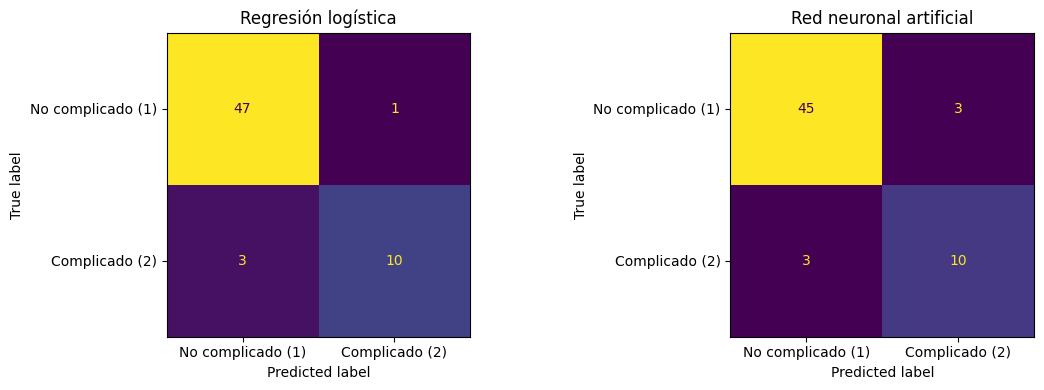


 Regresión logística
              precision    recall  f1-score   support

           1       0.94      0.98      0.96        48
           2       0.91      0.77      0.83        13

    accuracy                           0.93        61
   macro avg       0.92      0.87      0.90        61
weighted avg       0.93      0.93      0.93        61


 Red neuronal artificial
              precision    recall  f1-score   support

           1       0.94      0.94      0.94        48
           2       0.77      0.77      0.77        13

    accuracy                           0.90        61
   macro avg       0.85      0.85      0.85        61
weighted avg       0.90      0.90      0.90        61



In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (nombre, metrica) in zip(axes, evaluaciones.items()):
    ConfusionMatrixDisplay(
        confusion_matrix=metrica["confusion_matrix"],
        display_labels=["No complicado (1)", "Complicado (2)"]
    ).plot(ax=ax, colorbar=False, values_format="d")
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

for nombre, metrica in evaluaciones.items():
    print("\n", nombre)
    print(metrica["report"])

## 11. Ejemplo de predicción individual

Se toma una observación del conjunto de prueba y se muestra la predicción de cada modelo junto con las probabilidades estimadas. Es una demostración técnica con un registro existente del dataset, no un resultado clínico.

In [27]:
registro_demo = X_test.iloc[[0]].copy()
print("Datos de entrada:")
display(registro_demo)
print("Etiqueta real:", y_test.iloc[0])

for nombre, modelo in modelos_entrenados.items():
    clase = str(modelo.predict(registro_demo)[0])
    probabilidades = modelo.predict_proba(registro_demo)[0]
    tabla = pd.DataFrame({
        "Clase": [str(x) for x in modelo.classes_],
        "Probabilidad": probabilidades
    }).sort_values("Probabilidad", ascending=False)
    print(f"\n{nombre}: clase predicha = {clase}")
    display(tabla)

Datos de entrada:


,AGE,GENDER,DURATION OF FEVER,HEADACHE,MYALGIA,ABDOMINAL PAIN,RASH,VOMITING,BREATHLESSNESS,BLEEDING,...,HB,PCV,LOWEST WBC,HIGHEST WBC,PLATELET COUNT,ALT,CREATININE,FERRITIN,WBC_RANGE,PLATELET_WBC_RATIO
87,Mayor de 6 años,Masculino,1,No,No,No,No,Sí,No,No,...,13.5,41.7,2700,4900,142000,15.0,0.6,NaN,2200,28.979592


Etiqueta real: 1

Regresión logística: clase predicha = 1


,Clase,Probabilidad
0,1,0.735873
1,2,0.264127



Red neuronal artificial: clase predicha = 2


,Clase,Probabilidad
1,2,0.568377
0,1,0.431623


## 12. Guardar resultados para conectarlos a la página web

Al ejecutar esta celda se guardan: (1) los pipelines entrenados en `models/modelos_dengue.joblib`, (2) la base limpia en CSV y (3) las métricas y matrices de confusión en JSON. La aplicación web comprueba que el archivo de modelos corresponda a la misma base y selección de variables antes de cargarlo.

In [28]:
def dataframe_signature(df: pd.DataFrame) -> str:
    content = pd.util.hash_pandas_object(df, index=True).values.tobytes()
    content += "|".join(map(str, df.columns)).encode("utf-8", errors="ignore")
    return hashlib.sha256(content).hexdigest()

MODELS_DIR = PROJECT_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

# Datos de referencia usados por el formulario de predicción individual de la web.
referencia_prediccion = df_limpio[features].copy()

bundle_web = {
    "models": modelos_entrenados,
    "target": TARGET,
    "features": features,
    "evaluation": evaluaciones,
    "n_rows": resultado_entrenamiento["n_rows"],
    "n_train": resultado_entrenamiento["n_train"],
    "n_test": resultado_entrenamiento["n_test"],
    "test_size": resultado_entrenamiento["test_size"],
    "class_counts": resultado_entrenamiento["class_counts"],
    "convergence_warnings": resultado_entrenamiento["convergence_warnings"],
    "reference_df": referencia_prediccion,
    "clean_summary": resumen_limpieza,
    "data_signature": dataframe_signature(df_limpio),
    "source_name": DATA_PATH.name,
    "version": 2
}

model_path = MODELS_DIR / "modelos_dengue.joblib"
joblib.dump(bundle_web, model_path)

clean_path = PROJECT_DIR / "data" / "base_dengue_limpia.csv"
df_limpio.to_csv(clean_path, index=False, sep=";", encoding="utf-8-sig")

# También se guarda una versión XLSX: Excel conserva las columnas y reconoce
# correctamente los valores numéricos sin depender del separador regional.
excel_clean_path = PROJECT_DIR / "data" / "base_dengue_limpia.xlsx"
with pd.ExcelWriter(excel_clean_path, engine="openpyxl") as writer:
    df_limpio.to_excel(writer, index=False, sheet_name="Base limpia")
    worksheet = writer.sheets["Base limpia"]
    worksheet.freeze_panes = "A2"
    worksheet.auto_filter.ref = worksheet.dimensions
    from openpyxl.styles import Font, PatternFill, Alignment
    for cell in worksheet[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = PatternFill("solid", fgColor="174A6E")
        cell.alignment = Alignment(wrap_text=True, vertical="center")
    worksheet.row_dimensions[1].height = 32
    for column_cells in worksheet.columns:
        column_letter = column_cells[0].column_letter
        max_length = max((len(str(cell.value)) if cell.value is not None else 0) for cell in column_cells)
        worksheet.column_dimensions[column_letter].width = min(max(max_length + 2, 12), 35)

metricas_json = {}
for nombre, metrica in evaluaciones.items():
    metricas_json[nombre] = {
        "accuracy": metrica["accuracy"],
        "precision_ponderada": metrica["precision"],
        "sensibilidad_ponderada": metrica["recall"],
        "f1_ponderado": metrica["f1"],
        "etiquetas": [str(x) for x in metrica["labels"]],
        "matriz_confusion": np.asarray(metrica["confusion_matrix"]).tolist(),
        "reporte": metrica["report"]
    }
metrics_path = PROJECT_DIR / "data" / "metricas_modelos.json"
metrics_path.write_text(json.dumps(metricas_json, ensure_ascii=False, indent=2), encoding="utf-8")

print("Modelos guardados en:", model_path)
print("Base limpia guardada en:", clean_path)
print("Métricas guardadas en:", metrics_path)
print("Firma del dataset:", bundle_web["data_signature"])

Modelos guardados en: C:\Users\pc\Downloads\Proyecto_Final_Dengue_Completo_CORREGIDO\proyecto_analitica_web\models\modelos_dengue.joblib
Base limpia guardada en: C:\Users\pc\Downloads\Proyecto_Final_Dengue_Completo_CORREGIDO\proyecto_analitica_web\data\base_dengue_limpia.csv
Métricas guardadas en: C:\Users\pc\Downloads\Proyecto_Final_Dengue_Completo_CORREGIDO\proyecto_analitica_web\data\metricas_modelos.json
Firma del dataset: c36ac937aa4e80f2d6674dbe698877390aa56149395b141b1894d50d5cc800d6
